# Iris Classification with k-Nearest Neighbors
Author: Manuel Eugenio Morocho Cayamcela, PhD
Editado by: Nicole Carolina Benavides Leal

## Introduction
Use supervised learning to classify 150 Iris flowers into three species from four measurements: sepal length, sepal width, petal length, and petal width (in centimeters). This lesson covers loading data, exploration, preprocessing, training a k-nearest neighbors (k-NN) classifier, saving the model, and evaluating predictions.

![image.png](attachment:image.png)

## Setup
If needed, install the packages once with `%pip install pandas matplotlib seaborn scikit-learn joblib`. Restart the kernel after installation if requested.

In [50]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

## Load the Iris dataset
Read the Iris CSV directly from GitHub using pandas. An internet connection is required.

In [51]:
github_url = "https://raw.githubusercontent.com/eugeniomorocho/ArtificialIntelligence/main/Datasets/iris.csv"
iris = pd.read_csv(github_url)

## Explore and prepare the data
Run each cell separately and inspect its output before continuing.

Preview the first five records.

In [52]:
iris.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


Inspect column types and non-null counts to identify missing values.

In [53]:
iris.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


Summarize the numeric columns.

In [54]:
iris.describe()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


Count the examples of each species.

In [55]:
iris["Species"].value_counts()

,count
Species,
Iris-setosa,50
Iris-versicolor,50
Iris-virginica,50


Remove `Id`: it identifies records rather than measuring flowers.

In [56]:
iris = iris.drop(columns="Id")

## Visualize the measurements
Compare sepal and petal measurements by species. Setosa is particularly distinct in petal measurements; versicolor and virginica overlap more. These plots help assess whether the measurements can separate the classes.

### Sepal measurements

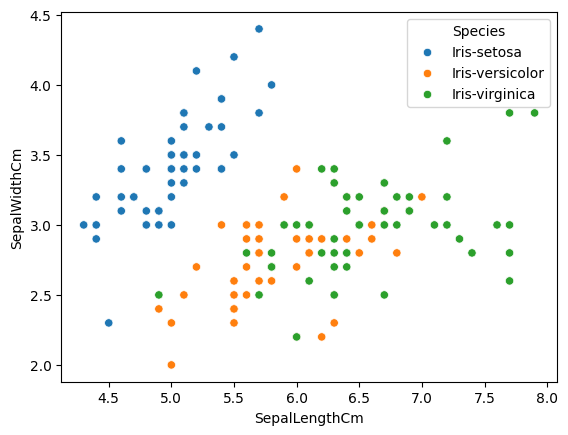

In [57]:
sns.scatterplot(data=iris, x="SepalLengthCm", y="SepalWidthCm", hue="Species")
plt.show()

### Petal measurements

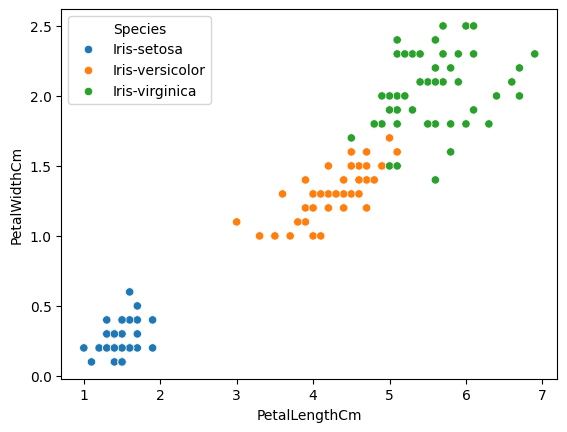

In [58]:
sns.scatterplot(data=iris, x="PetalLengthCm", y="PetalWidthCm", hue="Species")
plt.show()

The pair plot compares every pair of measurements. Histograms on the diagonal show each feature's distribution.

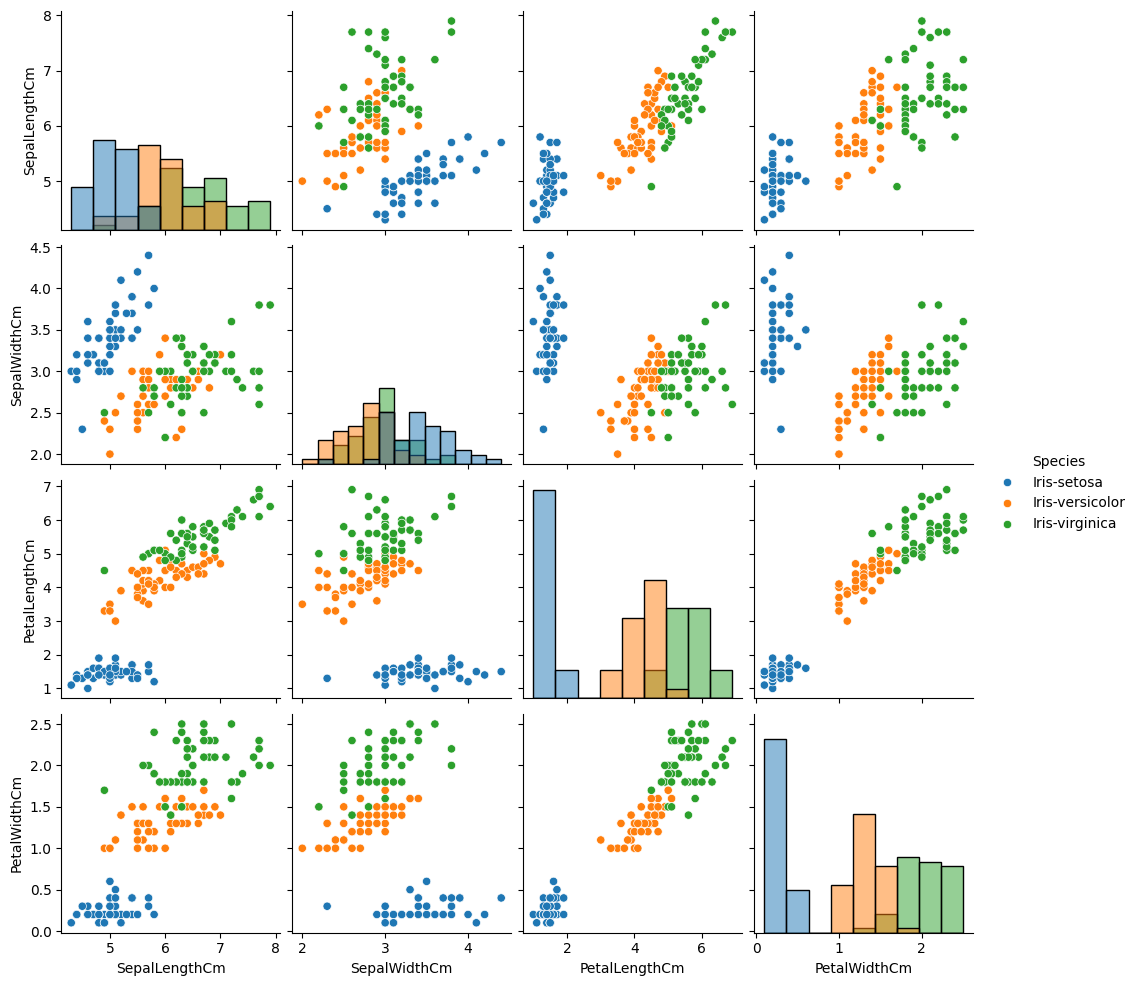

In [59]:
sns.pairplot(iris, hue="Species", diag_kind="hist")
plt.show()

## Prepare training and test sets
Separate the four predictors (`X`) from the species label (`y`). Reserve 20% of the data for testing. Stratification preserves class proportions, and a fixed random seed makes the split reproducible. Keep the test set out of model fitting.

In [60]:
# Isolate features
X = iris.drop(columns="Species")

# Isolate target variable
y = iris["Species"]

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

## Train the k-NN classifier
With `n_neighbors=5`, the classifier predicts a flower's species from the majority class among its five nearest training examples. Fit the model on the training set only.

In [61]:
from sklearn.neighbors import KNeighborsClassifier

classifier = KNeighborsClassifier(n_neighbors=5)
classifier.fit(X_train, y_train)

KNeighborsClassifier()

## Evaluate on unseen data
Predict the species of the held-out examples.

In [62]:
predictions = classifier.predict(X_test)

### Accuracy
Accuracy is the fraction of correctly classified test examples.

In [63]:
print(f"Test accuracy: {accuracy_score(y_test, predictions):.3f}")

Test accuracy: 1.000


### Classification report
The report summarizes each species:

- **Precision:** TP / (TP + FP), the fraction of predictions for that species that are correct.
- **Recall:** TP / (TP + FN), the fraction of actual flowers of that species correctly identified.
- **F1-score:** the harmonic mean of precision and recall.
- **Support:** the number of true examples of that species in the test set.

Interpret the results generated below; scores can change with the split and model settings.

In [64]:
print(classification_report(y_test, predictions, zero_division=0))

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      1.00      1.00        10
 Iris-virginica       1.00      1.00      1.00        10

       accuracy                           1.00        30
      macro avg       1.00      1.00      1.00        30
   weighted avg       1.00      1.00      1.00        30



### Confusion matrix
Rows show actual classes and columns show predicted classes. Diagonal entries are correct predictions.

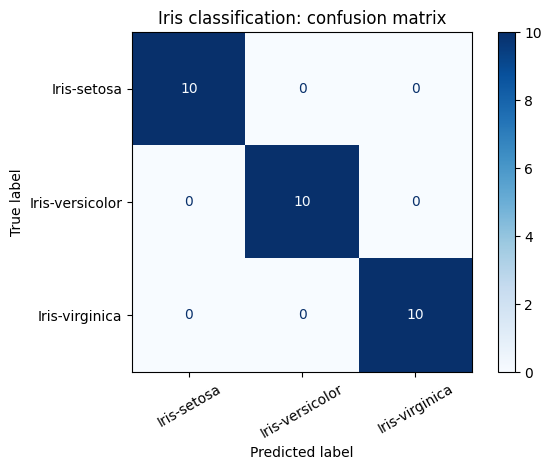

In [65]:
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions, labels=classifier.classes_, cmap="Blues"
)
plt.title("Iris classification: confusion matrix")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Save and reload the trained model
Save the fitted classifier for reuse without retraining. Only load model files you trust. The file is written to the current working directory.

In [66]:
import joblib

model_path = Path("knn_model.pkl")
joblib.dump(classifier, model_path)

['knn_model.pkl']

In [67]:
loaded_classifier = joblib.load(model_path)
loaded_classifier.predict(X_test.head())

array(['Iris-setosa', 'Iris-virginica', 'Iris-versicolor',
       'Iris-versicolor', 'Iris-setosa'], dtype=object)

## Activity: Data Preprocessing and Customer Classification with k-NN
### Objective
Explore a classification dataset, train k-NN, and select a suitable value of `k`. Work individually or in a group, share the work fairly, and justify your decisions.

### Where to find datasets
For this short activity, choose a small tabular dataset with a clearly documented categorical target. Prefer CSV files and numeric predictors so that data preparation remains manageable.

- [UCI Machine Learning Repository](https://archive.ics.uci.edu/): a useful starting point for classification datasets.
- [Kaggle Datasets](https://www.kaggle.com/datasets): browse datasets and select one with a documented target and downloadable tabular files. Check access requirements before choosing it.
- [Awesome Public Datasets on GitHub](https://github.com/awesomedata/awesome-public-datasets): a topic-based directory linking to datasets; check the original source for files and documentation.
- [Ecuador Open Data Portal — CSV datasets](https://www.datosabiertos.gob.ec/dataset/?res_format=CSV): explore Ecuadorian public data available in CSV format.
- [INEC Open Data Bank](https://aplicaciones3.ecuadorencifras.gob.ec/BIINEC-war/index.xhtml): find Ecuadorian statistical information and consult the accompanying documentation.
- [U.S. Government Open Data](https://data.gov/): search public datasets by topic or organization.

Government portals are useful for local or applied topics, but their tables may require more cleaning and may not have a ready-made classification target. Verify the target column and download format before committing to a dataset.

### Instructions
1. **Find and explore a dataset (10 minutes).** Load a classification dataset, inspect its structure, and clean or transform it as needed.

In [68]:
# Import the dataset

import pandas as pd

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00267/data_banknote_authentication.txt"

columnas = ["variance", "skewness", "curtosis", "entropy", "class"]

df = pd.read_csv(url, header=None, names=columnas)

# Visualizar los primeros registros
df.head()


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


In [69]:
# Exploración inicial del dataset

print("Dimensiones del dataset:")
print(df.shape)

print("\nInformación de las variables:")
df.info()

print("\nValores faltantes por columna:")
print(df.isnull().sum())

print("\nDistribución de las clases:")
print(df["class"].value_counts())


Dimensiones del dataset:
(1372, 5)

Información de las variables:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   variance  1372 non-null   float64
 1   skewness  1372 non-null   float64
 2   curtosis  1372 non-null   float64
 3   entropy   1372 non-null   float64
 4   class     1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB

Valores faltantes por columna:
variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64

Distribución de las clases:
class
0    762
1    610
Name: count, dtype: int64


**Análisis exploratorio del conjunto de datos**

Se seleccionó el conjunto de datos Banknote Authentication, disponible en el repositorio UCI Machine Learning, con el propósito de desarrollar un modelo de clasificación supervisada mediante el algoritmo k-NN.

El conjunto contiene 1.372 registros y cinco columnas, de las cuales cuatro corresponden a características numéricas y una representa la variable objetivo (class).

Durante la exploración inicial se comprobó que no existen valores faltantes. Además, se identificaron 762 registros de la clase 0 y 610 de la clase 1, lo que evidencia una diferencia moderada en su distribución.

Por lo tanto, no se requiere imputación de valores faltantes. Sin embargo, será necesario estandarizar las variables predictoras, debido a que el algoritmo k-NN calcula distancias entre observaciones y puede verse afectado por las diferentes escalas de los datos.

In [70]:
from sklearn.model_selection import train_test_split

# Variables predictoras
X = df.drop(columns=["class"])

# Variable objetivo
y = df["class"]

# División del dataset: 80% entrenamiento y 20% prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Registros de entrenamiento:", X_train.shape[0])
print("Registros de prueba:", X_test.shape[0])

print("\nDistribución de clases en entrenamiento:")
print(y_train.value_counts())

print("\nDistribución de clases en prueba:")
print(y_test.value_counts())


Registros de entrenamiento: 1097
Registros de prueba: 275

Distribución de clases en entrenamiento:
class
0    609
1    488
Name: count, dtype: int64

Distribución de clases en prueba:
class
0    153
1    122
Name: count, dtype: int64


2. **Classify with k-NN (20 minutes).** Split the data into training and test sets, train the classifier, and report accuracy. Select `k` using only training data (for example, cross-validation), then evaluate the chosen model on the test set. Predict a new example outside both sets. Complete the random forest comparison in the companion notebook.

In [71]:
# Select the best k value for the k-NN classifier

from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Crear un pipeline de escalado y clasificación
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

# Valores de k que vamos a comparar
parametros = {
    "knn__n_neighbors": list(range(1, 31))
}

# Validación cruzada estratificada de 5 particiones
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Buscar el mejor valor de k
busqueda = GridSearchCV(
    estimator=pipeline,
    param_grid=parametros,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

# Entrenar utilizando únicamente los datos de entrenamiento
busqueda.fit(X_train, y_train)

print("Mejor valor de k:", busqueda.best_params_["knn__n_neighbors"])
print("Mejor accuracy promedio en validación cruzada:",
      round(busqueda.best_score_, 4))


Mejor valor de k: 10
Mejor accuracy promedio en validación cruzada: 0.9991


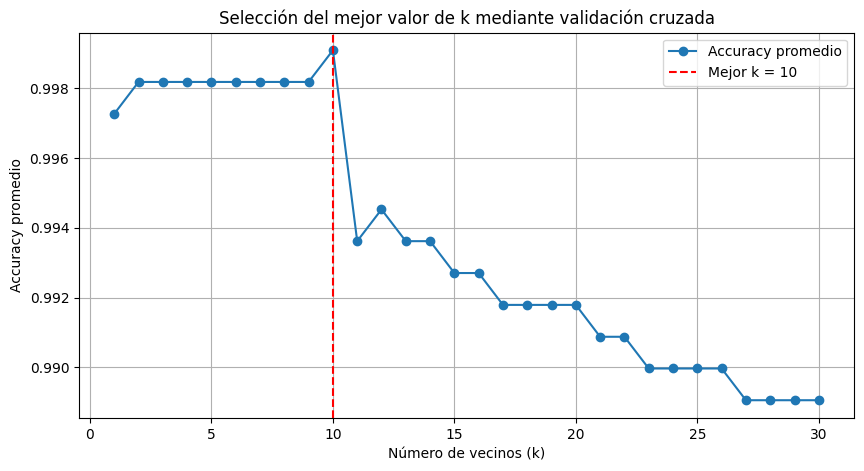

In [72]:
# Comparación de los diferentes valores de k

import matplotlib.pyplot as plt
import pandas as pd

# Obtener los resultados de validación cruzada
resultados_k = pd.DataFrame(busqueda.cv_results_)

valores_k = resultados_k["param_knn__n_neighbors"].astype(int)
accuracy_k = resultados_k["mean_test_score"]

mejor_k = busqueda.best_params_["knn__n_neighbors"]

# Crear gráfico
plt.figure(figsize=(10, 5))

plt.plot(valores_k, accuracy_k, marker="o", label="Accuracy promedio")

plt.axvline(
    x=mejor_k,
    color="red",
    linestyle="--",
    label=f"Mejor k = {mejor_k}"
)

plt.xlabel("Número de vecinos (k)")
plt.ylabel("Accuracy promedio")
plt.title("Selección del mejor valor de k mediante validación cruzada")
plt.legend()
plt.grid(True)
plt.show()


**Selección y justificación del valor óptimo de k**

Para seleccionar el número de vecinos más adecuado, se evaluaron valores de k entre 1 y 30 mediante validación cruzada estratificada de cinco particiones, utilizando únicamente los datos de entrenamiento.

Se aplicó StandardScaler dentro de un Pipeline para estandarizar las variables predictoras sin introducir información de los conjuntos de validación durante el entrenamiento.

Los resultados muestran que k = 10 alcanzó la mayor exactitud promedio, con aproximadamente un 99,91%. Aunque otros valores también presentaron resultados elevados, a partir de k = 11 se observa una tendencia general descendente en el rendimiento.

Por esta razón, se seleccionó k = 10 como el hiperparámetro del modelo definitivo, considerando su desempeño en validación cruzada. Posteriormente, se evaluará su capacidad de clasificación con los datos de prueba que no participaron en la selección del modelo.

In [73]:
# Evaluación final del modelo k-NN

from sklearn.metrics import accuracy_score, classification_report

# Recuperar el mejor modelo entrenado
modelo_final = busqueda.best_estimator_

# Predecir sobre el conjunto de prueba
predicciones_finales = modelo_final.predict(X_test)

# Calcular la exactitud
accuracy_final = accuracy_score(y_test, predicciones_finales)

print("Mejor valor de k:", busqueda.best_params_["knn__n_neighbors"])
print(f"Accuracy en prueba: {accuracy_final:.4f}")
print(f"Porcentaje de aciertos: {accuracy_final * 100:.2f}%")

print("\nReporte de clasificación:")
print(classification_report(y_test, predicciones_finales))


Mejor valor de k: 10
Accuracy en prueba: 1.0000
Porcentaje de aciertos: 100.00%

Reporte de clasificación:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       153
           1       1.00      1.00      1.00       122

    accuracy                           1.00       275
   macro avg       1.00      1.00      1.00       275
weighted avg       1.00      1.00      1.00       275



<Figure size 700x500 with 0 Axes>

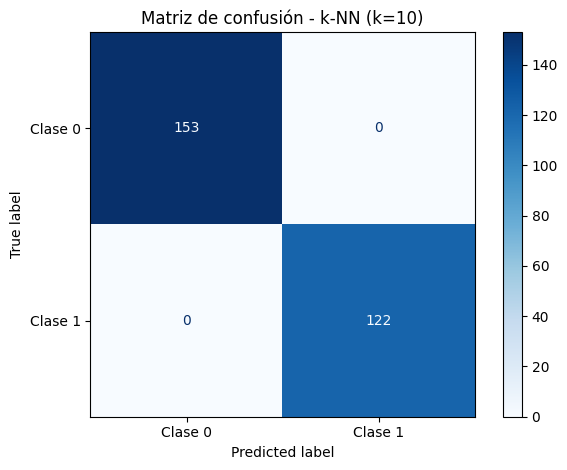

In [74]:
# Matriz de confusión del modelo k-NN

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predicciones_finales,
    display_labels=["Clase 0", "Clase 1"],
    cmap="Blues",
    values_format="d"
)

plt.title("Matriz de confusión - k-NN (k=10)")
plt.tight_layout()
plt.show()


In [75]:
# Predicción de un nuevo billete

import pandas as pd

# Crear un nuevo ejemplo hipotético
nuevo_billete = pd.DataFrame({
    "variance": [3.5],
    "skewness": [7.2],
    "curtosis": [-2.1],
    "entropy": [-0.8]
})

# Realizar la predicción
prediccion_nueva = modelo_final.predict(nuevo_billete)

print("Características del nuevo billete:")
print(nuevo_billete)

print("\nClase predicha:", prediccion_nueva[0])

if prediccion_nueva[0] == 0:
    print("Resultado: Billete clasificado como auténtico")
else:
    print("Resultado: Billete clasificado como falsificado")


Características del nuevo billete:
   variance  skewness  curtosis  entropy
0       3.5       7.2      -2.1     -0.8

Clase predicha: 0
Resultado: Billete clasificado como auténtico


**Identificación de las clases**

La variable objetivo del conjunto de datos es class, que permite clasificar los billetes en dos categorías:

Clase 0: corresponde a billetes auténticos, con 762 registros.

Clase 1: corresponde a billetes falsificados, con 610 registros.

El objetivo del modelo k-NN es identificar a cuál de estas dos clases pertenece un nuevo billete a partir de cuatro características numéricas extraídas de su imagen.

La distribución de las clases presenta una diferencia moderada, por lo que se utilizó una división estratificada de los datos para conservar sus proporciones durante el entrenamiento y la evaluación.

3. **Present the dataset and process (30 minutes).** Explain decisions and results, and discuss possible improvements.


###**Análisis de resultados y evaluación del modelo k-NN**

**Descripción del conjunto de datos**

Se utilizó el dataset Banknote Authentication del repositorio UCI Machine Learning, compuesto por 1.372 registros y cuatro características numéricas extraídas de imágenes de billetes. El objetivo fue desarrollar un modelo de aprendizaje supervisado para diferenciar billetes auténticos de falsificados.

**Preprocesamiento de los datos**

Se verificó que el conjunto de datos no presentara valores faltantes. Posteriormente, se dividió en un 80% para entrenamiento (1.097 registros) y un 20% para prueba (275 registros), conservando la proporción de las dos clases mediante una división estratificada.

Además, se utilizó StandardScaler dentro de un Pipeline para estandarizar las variables y evitar fugas de información durante la validación cruzada.

**Selección del valor de k**

Se compararon valores de k entre 1 y 30 mediante validación cruzada de cinco particiones. El mejor resultado correspondió a k = 10, con una exactitud promedio del 99,91%.

**Evaluación del modelo**

Al evaluar el modelo definitivo sobre los 275 registros de prueba, se obtuvo una exactitud del 100%, con valores de precisión, recall y F1-score de 1,00 para ambas clases.

La matriz de confusión confirmó 153 clasificaciones correctas de la clase 0 y 122 de la clase 1, sin errores en este conjunto de prueba.

Finalmente, se realizó una predicción sobre un registro hipotético nuevo, que el modelo clasificó como clase 0.

**Posibles mejoras**

Aunque los resultados fueron elevados, sería conveniente evaluar el algoritmo con otros conjuntos de datos, comparar diferentes métricas y comprobar su desempeño en condiciones más cercanas a una aplicación real.

**Conclusión**

El algoritmo k-NN demostró un desempeño elevado en la clasificación de este conjunto de datos. La estandarización, la selección de k mediante validación cruzada y la separación de los datos de prueba permitieron desarrollar una evaluación reproducible y metodológicamente adecuada.

Sin embargo, el resultado del 100% debe interpretarse dentro de las condiciones del experimento y no como garantía de precisión absoluta frente a nuevos datos.

###**4. Comparación con Random Forest**

In [76]:
# Comparación k-NN vs Random Forest

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Crear el modelo Random Forest
modelo_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Entrenar con los mismos datos utilizados en k-NN
modelo_rf.fit(X_train, y_train)

# Realizar predicciones
predicciones_rf = modelo_rf.predict(X_test)

# Evaluar resultados
accuracy_rf = accuracy_score(y_test, predicciones_rf)

print("COMPARACIÓN DE MODELOS")
print("------------------------------")
print(f"Accuracy k-NN: {accuracy_final * 100:.2f}%")
print(f"Accuracy Random Forest: {accuracy_rf * 100:.2f}%")

print("\nReporte de clasificación Random Forest:")
print(classification_report(y_test, predicciones_rf))


COMPARACIÓN DE MODELOS
------------------------------
Accuracy k-NN: 100.00%
Accuracy Random Forest: 99.64%

Reporte de clasificación Random Forest:
              precision    recall  f1-score   support

           0       1.00      0.99      1.00       153
           1       0.99      1.00      1.00       122

    accuracy                           1.00       275
   macro avg       1.00      1.00      1.00       275
weighted avg       1.00      1.00      1.00       275



##**Comparación de resultados: k-NN y Random Forest**

Con la finalidad de comparar el desempeño de diferentes algoritmos de aprendizaje supervisado, se entrenó un modelo Random Forest utilizando 100 árboles de decisión y los mismos conjuntos de entrenamiento y prueba empleados para k-NN.

Los resultados evidenciaron que k-NN obtuvo una exactitud del 100%, mientras que Random Forest alcanzó el 99,64%.

Esto significa que k-NN clasificó correctamente los 275 registros de prueba, mientras que Random Forest clasificó correctamente 274, presentando un único error.

Por lo tanto, k-NN presentó un desempeño ligeramente superior en este experimento. Sin embargo, la diferencia es pequeña y no permite concluir que sea superior en todos los escenarios.

Como posible mejora, se recomienda evaluar ambos algoritmos mediante validación cruzada repetida y probar diferentes configuraciones de hiperparámetros para obtener una comparación más robusta.

### Assessment
- Dataset source: 10%.
- Training/test split: 20%.
- Justification of the chosen `k`: 40%.
- Classification metrics: 30%.

### Deliverable
Submit the Jupyter notebook results as a PDF.